# 02b. Dimensionality Reduction and Feature-Group Ablation

**Owner:** Member B (Random Forest)
**Step 8 (joint):** this notebook is the first half. `02c_feature_selection.ipynb` (Member A) covers filter and embedded feature selection and makes the joint decision on the final feature set, using the results saved here.

**Question answered here:** does the model need every kind of information it is given, and does compressing the inputs with PCA help?

**How every option is scored**

* Both project algorithms at **fixed reference settings** (`src/evaluation.py`): Logistic Regression and Random Forest, each with class weighting. Nothing is tuned here; the aim is to compare inputs, not settings.
* The five expanding-window cross-validation folds from step 7 (validation years 2016 to 2020).
* **PR-AUC** (average precision), the primary metric. The no-model persistence rule is shown as a baseline.
* All preprocessing, including PCA, is fitted on each fold's training rows only.

The 2021 to 2022 validation years and the 2023 to 2025 test set are not used.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from src import config, viz
from src.evaluation import compare_to_reference, cross_validate, fold_table, persistence_scores, summarise
from src.preprocessing import (
    CV_VALIDATION_YEARS, FEATURE_GROUPS, MODEL_FEATURES, build_model_frame,
    expanding_year_folds, make_district_encoder, make_numeric_transformer, make_preprocessor,
)

viz.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
frame = build_model_frame()
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
X, y = train_frame[MODEL_FEATURES], train_frame["target"]
folds = expanding_year_folds(train_frame)

print(f"Training rows: {len(X):,}   Folds: {len(folds)} (validation years {CV_VALIDATION_YEARS[0]} to {CV_VALIDATION_YEARS[-1]})")
print("Feature groups:")
for group, columns in FEATURE_GROUPS.items():
    print(f"  {group:13s} {len(columns):2d} features: {', '.join(columns)}")

Training rows: 18,200   Folds: 5 (validation years 2016 to 2020)
Feature groups:
  case history  10 features: cases_now, cases_lag1, cases_lag2, cases_lag3, cases_lag4, cases_roll4, cases_roll8, cases_rel_threshold, cases_trend, outbreak_now
  climate        4 features: rain_recent4, rain_w5_8, humidity_w5_8, temp_max_anom4
  calendar       2 features: week_sin, week_cos
  district       2 features: log_density, district


## 1. Reference point: all features

Every other setting is compared with this one.

In [3]:
all_features = cross_validate(lambda: make_preprocessor(), X, y, folds, label="all features")
persistence = persistence_scores(train_frame, folds)
reference = pd.concat([all_features, persistence])

summarise(reference)

mean PR-AUC  std across folds
setting              model                                             
all features         Logistic Regression        0.686             0.266
                     Random Forest              0.676             0.246
persistence baseline Persistence                0.496             0.270

In [4]:
fold_table(reference, CV_VALIDATION_YEARS)

2016  2017  2018  2019  2020
setting              model                                            
all features         Logistic Regression 0.279 0.849 0.552 0.912 0.838
                     Random Forest       0.284 0.769 0.598 0.896 0.834
persistence baseline Persistence         0.121 0.741 0.336 0.749 0.535

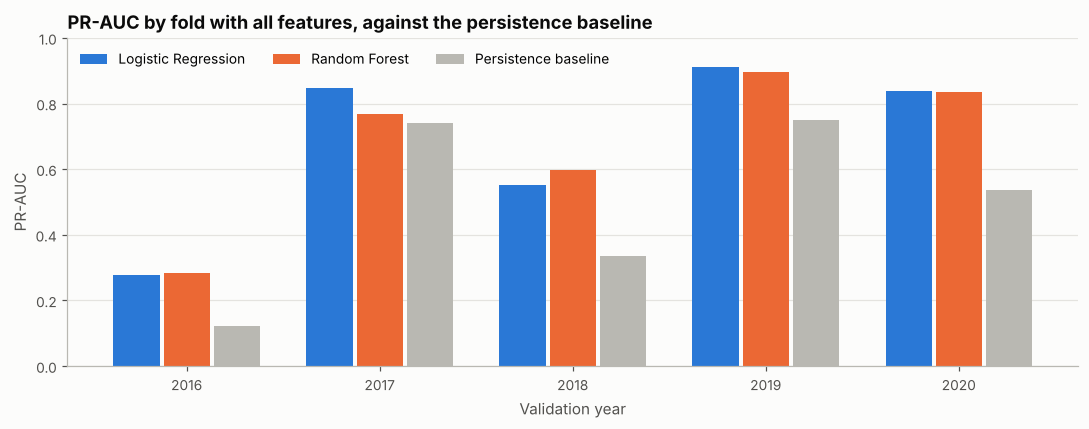

In [5]:
by_fold = fold_table(reference, CV_VALIDATION_YEARS)
series = [("Logistic Regression", ("all features", "Logistic Regression"), viz.BLUE),
          ("Random Forest", ("all features", "Random Forest"), viz.ORANGE),
          ("Persistence baseline", ("persistence baseline", "Persistence"), viz.NEUTRAL)]

fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(CV_VALIDATION_YEARS))
width = 0.26
for i, (label, key, colour) in enumerate(series):
    ax.bar(positions + (i - 1) * width, by_fold.loc[key].to_numpy(), width=width * 0.92, color=colour, label=label)
ax.set_xticks(positions)
ax.set_xticklabels([f"{year}" for year in CV_VALIDATION_YEARS])
ax.set_xlabel("Validation year")
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
ax.set_title("PR-AUC by fold with all features, against the persistence baseline")
fig.tight_layout()
viz.save(fig, "dr_01_reference_by_fold")
plt.show()

**Finding.** With all features, both algorithms beat the persistence baseline in every fold, by about 0.18 to 0.19 PR-AUC on average. Scores vary far more between years than between the two algorithms. 2016, a quiet year with few outbreaks to find, is by far the hardest fold (PR-AUC about 0.28), while 2019 is the easiest (about 0.90). The 2017 epidemic is easier for Logistic Regression than for Random Forest.

**Implication for the comparisons below.** Because the year matters more than the setting, a change of 0.01 in the mean could come from one unusual fold. Each setting is therefore compared with this reference **fold by fold**, reporting how many of the five folds improved or got worse, not just the average change.

## 2. Feature-group ablation

Each group is removed in turn and the models are rescored. A large drop means the group carries information the others cannot replace. The humidity window is also tested on its own, because preprocessing (02a section 7) found it no more informative than the raw humidity column.

In [6]:
ablation_runs = [all_features]
for group, columns in FEATURE_GROUPS.items():
    kept = [f for f in MODEL_FEATURES if f not in columns]
    ablation_runs.append(cross_validate(lambda kept=kept: make_preprocessor(kept), X, y, folds, label=f"without {group}"))

kept = [f for f in MODEL_FEATURES if f != "humidity_w5_8"]
ablation_runs.append(cross_validate(lambda: make_preprocessor(kept), X, y, folds, label="without humidity_w5_8"))

ablation = pd.concat(ablation_runs)
ablation_comparison = compare_to_reference(ablation, "all features")
ablation_comparison

mean PR-AUC  change vs reference  folds better  folds worse
setting               model                                                                           
without case history  Logistic Regression        0.225               -0.461             0            5
                      Random Forest              0.230               -0.446             0            5
without climate       Logistic Regression        0.673               -0.013             0            5
                      Random Forest              0.668               -0.008             2            3
without calendar      Logistic Regression        0.682               -0.004             3            2
                      Random Forest              0.665               -0.011             1            4
without district      Logistic Regression        0.696                0.010             4            1
                      Random Forest              0.666               -0.010             1            4
without humidity_w5_8 Logistic Regression        0.686               -0.000             1            4
                      Random Forest              0.672               -0.004             1            4

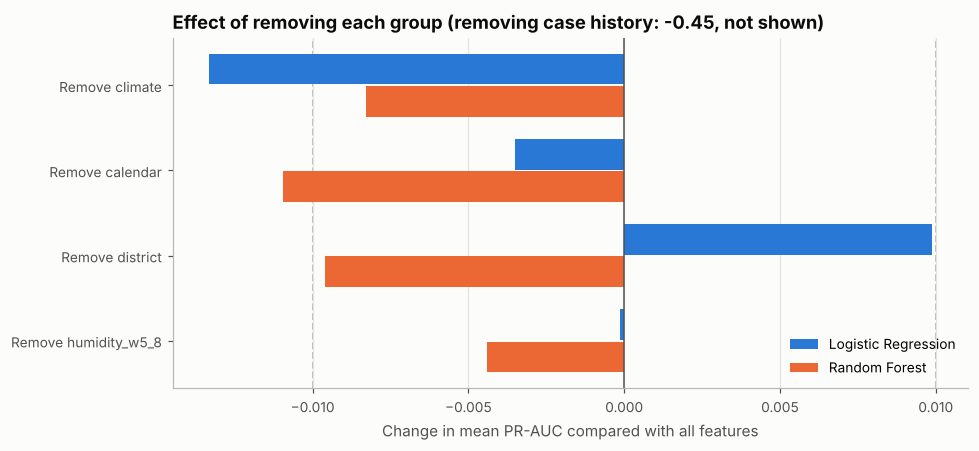

In [7]:
small = ablation_comparison.drop(index="without case history", level="setting")
settings = list(dict.fromkeys(small.index.get_level_values("setting")))

fig, ax = plt.subplots(figsize=(9, 4.2))
positions = np.arange(len(settings))
for i, (model, colour) in enumerate([("Logistic Regression", viz.BLUE), ("Random Forest", viz.ORANGE)]):
    values = [small.loc[(s, model), "change vs reference"] for s in settings]
    ax.barh(positions + (i - 0.5) * 0.38, values, height=0.36, color=colour, label=model)
ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1, zorder=1)
for edge in (-0.01, 0.01):
    ax.axvline(edge, color=viz.NEUTRAL, linewidth=1.2, linestyle="--", zorder=0)
ax.set_yticks(positions)
ax.set_yticklabels([s.replace("without ", "Remove ") for s in settings])
ax.invert_yaxis()
ax.set_xlabel("Change in mean PR-AUC compared with all features")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
drop = ablation_comparison.xs("without case history", level="setting")["change vs reference"].mean()
ax.set_title(f"Effect of removing each group (removing case history: {drop:+.2f}, not shown)")
fig.tight_layout()
viz.save(fig, "dr_02_group_ablation")
plt.show()

The dashed lines mark a change of 0.01 either way, the tolerance agreed for the final decision.

**Findings.**

* **Case history is essential.** Removing it cuts PR-AUC by roughly two thirds, to about 0.23, worse than the persistence baseline. Every other group is secondary to it.
* **Climate helps a little.** Removing it lowers both models by about 0.01: Logistic Regression gets worse in all five folds and Random Forest in three. The effect is small but consistent, which fits the weak but real lagged relationships found in 01b.
* **Calendar helps Random Forest more than Logistic Regression.** The cyclical week features matter more to the tree model.
* **District divides the algorithms.** Removing it slightly *improves* Logistic Regression but worsens Random Forest. A linear model gains little from 25 district indicators once cases are scaled by each district's own threshold, while the forest can use district to form interactions.
* **The humidity window adds almost nothing.** Removing it changes both models by less than 0.01, consistent with 02a section 7, so it is a candidate for removal in the joint decision. The tiny losses are, however, consistent (four of five folds slightly worse for both models), so it may carry a faint signal. The joint decision should weigh that against the simpler feature set.

## 3. Dimensionality reduction with PCA

PCA replaces the 17 numeric features with a smaller number of uncorrelated components. District stays one-hot encoded, because PCA on indicator columns has no meaningful interpretation. PCA is fitted on each fold's training rows, after the same imputation, log transform and scaling as before.

### 3.1 How much variance do the components keep?

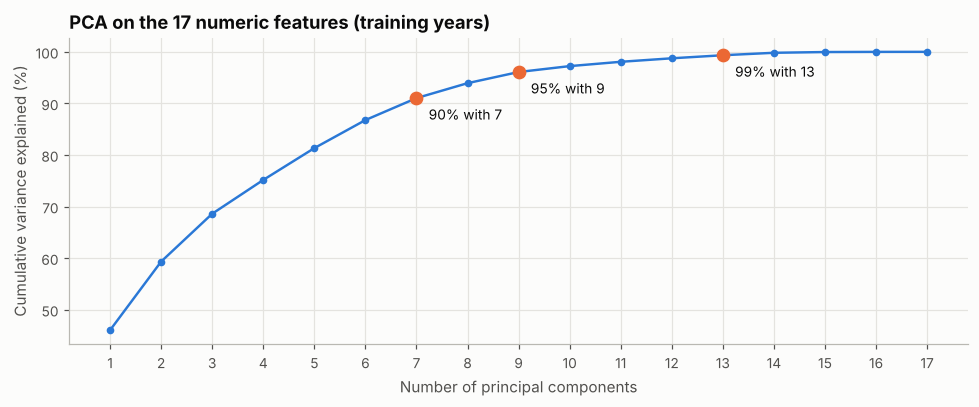

Components needed: 90% -> 7, 95% -> 9, 99% -> 13


In [8]:
numeric_features = [f for f in MODEL_FEATURES if f != config.DISTRICT_COL]
numeric_block = make_numeric_transformer(numeric_features).fit(X)
pca_full = PCA().fit(numeric_block.transform(X))
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
needed = {level: int(np.searchsorted(cumulative, level) + 1) for level in (0.90, 0.95, 0.99)}

fig, ax = plt.subplots(figsize=(9, 3.8))
components = np.arange(1, len(cumulative) + 1)
ax.plot(components, cumulative * 100, color=viz.BLUE, marker="o", markersize=4)
for level, n in needed.items():
    ax.plot(n, cumulative[n - 1] * 100, "o", color=viz.ORANGE, markersize=8)
    ax.annotate(f"{int(level * 100)}% with {n}", (n, cumulative[n - 1] * 100),
                xytext=(8, -14), textcoords="offset points", fontsize=9, color=viz.TEXT)
ax.set_xticks(components)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative variance explained (%)")
ax.set_title("PCA on the 17 numeric features (training years)")
fig.tight_layout()
viz.save(fig, "dr_03_pca_variance")
plt.show()

print("Components needed:", ", ".join(f"{int(k * 100)}% -> {v}" for k, v in needed.items()))

In [9]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=numeric_block.get_feature_names_out(),
                        columns=["PC1", "PC2", "PC3"])
print("Share of variance:", ", ".join(f"PC{i + 1} {v * 100:.0f}%" for i, v in enumerate(pca_full.explained_variance_ratio_[:3])))
loadings.round(2)

Share of variance: PC1 46%, PC2 13%, PC3 9%


,PC1,PC2,PC3
cases_now,0.340,-0.040,0.090
cases_lag1,0.340,-0.050,-0.040
cases_lag2,0.340,-0.060,-0.080
cases_lag3,0.330,-0.070,-0.120
cases_lag4,0.330,-0.090,-0.210
cases_roll4,0.350,-0.060,-0.040
cases_roll8,0.350,-0.070,-0.110
cases_rel_threshold,0.240,-0.180,0.470
rain_recent4,0.100,0.460,0.070
rain_w5_8,0.140,0.500,0.120


**Reading the components.** The first three have clear meanings:

* **PC1, case level:** the case counts, lags and rolling means all load strongly and almost equally (about 0.34 each). It is the district's current dengue burden, and it alone holds almost half the variance, because those features overlap heavily.
* **PC2, wet-season climate:** rainfall and humidity load positively, and the temperature anomaly negatively. It describes wet, cool spells.
* **PC3, outbreak momentum:** `cases_trend`, `outbreak_now` and the threshold ratio load together (about 0.5 each). It describes whether cases are rising towards or past the threshold.

### 3.2 Does PCA improve the models?

In [10]:
def pca_preprocessor(variance):
    """Numeric features compressed by PCA to the given share of variance; district one-hot encoded."""
    compressed = Pipeline([("numeric", make_numeric_transformer(numeric_features)),
                           ("pca", PCA(n_components=variance, random_state=config.RANDOM_SEED))])
    return ColumnTransformer([("pca", compressed, numeric_features),
                              ("district", make_district_encoder(), [config.DISTRICT_COL])])

pca_runs = [all_features] + [
    cross_validate(lambda v=v: pca_preprocessor(v), X, y, folds, label=f"PCA {int(v * 100)}% variance")
    for v in (0.90, 0.95, 0.99)
]
pca_results = pd.concat(pca_runs)
compare_to_reference(pca_results, "all features")

mean PR-AUC  change vs reference  folds better  folds worse
setting          model                                                                           
PCA 90% variance Logistic Regression        0.682               -0.004             2            3
                 Random Forest              0.648               -0.028             1            4
PCA 95% variance Logistic Regression        0.682               -0.004             2            3
                 Random Forest              0.659               -0.017             2            3
PCA 99% variance Logistic Regression        0.684               -0.002             2            3
                 Random Forest              0.666               -0.010             2            3

**Finding.** PCA does not improve either model. Logistic Regression is essentially unchanged at every level, because its L2 regularisation already copes with the moderate collinearity found in 01b (largest VIF 6.5). Random Forest gets worse, most at 90% variance: each component mixes many features, so the forest can no longer split on a single meaningful quantity such as "cases relative to the threshold".

PCA also removes interpretability. Coefficients and importances would describe components such as "case level" instead of individual features, which weakens the discussion in the report.

**Conclusion.** PCA is tested and **not adopted**. The compression it offers (17 features to 9 for 95% of the variance) brings no gain in performance and a clear loss in interpretability.

In [11]:
all_results = pd.concat([reference, ablation[ablation["setting"] != "all features"],
                         pca_results[pca_results["setting"] != "all features"]])
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
all_results.to_csv(config.METRICS_DIR / "dr_results_by_fold.csv", index=False)
compare_to_reference(all_results, "all features").to_csv(config.METRICS_DIR / "dr_comparison.csv")
loadings.round(4).to_csv(config.METRICS_DIR / "dr_pca_loadings.csv")
print("Saved fold-level results, comparison and PCA loadings to results/metrics/ for 02c_feature_selection")

Saved fold-level results, comparison and PCA loadings to results/metrics/ for 02c_feature_selection


## 4. Summary for the joint decision

| Setting | Logistic Regression | Random Forest | Verdict |
|---|---|---|---|
| All features | reference | reference | Both clearly beat persistence |
| Without case history | large drop | large drop | Essential |
| Without climate | small drop | small drop | Keep: small but consistent help |
| Without calendar | small drop | drop | Keep |
| Without district | small gain | drop | Algorithms disagree |
| Without humidity window | no change | negligible drop | **Candidate for removal** |
| PCA (90%, 95%, 99%) | no change | drop | **Not adopted** |

The fold-level results are saved to `results/metrics/dr_results_by_fold.csv`. `02c_feature_selection.ipynb` adds filter and embedded selection, then applies the agreed rule to all results together: the simplest feature set within 0.01 PR-AUC of the best, on both algorithms.